# 00 · Building the San Francisco dataset

This notebook walks through `src/vibecheck/filter_sf.py` one step at a time.
`make data` runs the same code from the terminal.

**Pipeline**

1. Download the California metadata (118 MB, 516k businesses).
2. Keep places in San Francisco that are cafes, restaurants or bars → `sf_places.parquet`.
3. Stream the California reviews file (5.35 GB) straight from the URL, keep up to the 50 most
   recent non-empty reviews per SF place → `sf_reviews.parquet`.

Both files are read line by line, so memory stays flat.

In [1]:
from itertools import islice

import matplotlib.pyplot as plt
import pandas as pd

from vibecheck import filter_sf as f
from vibecheck.plots import GROUP_COLORS, use_style

use_style()
pd.set_option("display.max_colwidth", 80)

## 1. What a raw record looks like

Each line of the metadata file is one business. `MISC` holds Google's attribute tags,
such as `Atmosphere: ["Casual", "Cozy"]`. We'll use those later to check search results.

In [2]:
f.download(f.META_URL, f.META_PATH)
sample = list(islice(f.iter_json_lines(f.META_PATH), 3))
pd.DataFrame(sample)[["name", "address", "category", "avg_rating", "num_of_reviews", "MISC"]]

meta-California.json.gz:   0%|          | 0.00/118M [00:00<?, ?B/s]

meta-California.json.gz:   0%|          | 8.03k/112M [00:00<00:09, 12.8MB/s]

,name,address,category,avg_rating,num_of_reviews,MISC
0,City Textile,"City Textile, 3001 E Pico Blvd, Los Angeles, CA 90023",[Textile exporter],4.5,6,None
1,San Soo Dang,"San Soo Dang, 761 S Vermont Ave, Los Angeles, CA 90005",[Korean restaurant],4.4,18,"{'Service options': ['Takeout', 'Dine-in', 'Delivery'], 'Accessibility': ['W..."
2,Nova Fabrics,"Nova Fabrics, 2200 E 11th St, Los Angeles, CA 90021",[Fabric store],3.3,6,"{'Service options': ['In-store shopping'], 'Payments': ['Checks', 'Debit car..."


## 2. The filter rules

All the knobs live at the top of `filter_sf.py`.

- **In SF**: the coordinates are inside the SF box, and the address says "San Francisco, CA" or names
  no other city. The address check drops the Daly City edge of the box. An address match alone
  isn't enough: "South San Francisco, CA" and SFO airport ("San Francisco, CA 94128") would sneak in.
- **Cafe / restaurant / bar**: a whole-word keyword match on Google's categories, so "bar" doesn't
  match "Barber shop", and "Restaurant supply store" is excluded.

In [3]:
print("SF box: lat", f.SF_LAT, "lon", f.SF_LON)
for group, words in f.CATEGORY_KEYWORDS.items():
    print(f"{group:>10}: {', '.join(words)}")
print("   exclude:", ", ".join(f.EXCLUDE_KEYWORDS))

SF box: lat (37.7, 37.83) lon (-122.52, -122.35)
      cafe: cafe, café, coffee, espresso, tea house, bubble tea, bakery
restaurant: restaurant, bistro, diner, eatery, steakhouse, steak house
       bar: bar, pub, lounge, tavern, brewpub, gastropub, brewery, taproom, night club, beer garden, beer hall
   exclude: supply, supplier, wholesaler, equipment, repair, manufacturer, distributor


In [4]:
places = f.build_places()
places.head()

meta-California.json.gz:   0%|          | 0.00/118M [00:00<?, ?B/s]

meta-California.json.gz:   4%|▍         | 4.96M/112M [00:00<00:02, 51.9MB/s]

meta-California.json.gz:   9%|▉         | 10.0M/112M [00:00<00:02, 52.5MB/s]

meta-California.json.gz:  13%|█▎        | 15.0M/112M [00:00<00:01, 52.5MB/s]

meta-California.json.gz:  18%|█▊        | 20.0M/112M [00:00<00:01, 52.5MB/s]

...

meta-California.json.gz:  92%|█████████▏| 104M/112M [00:02<00:00, 49.2MB/s] 

meta-California.json.gz:  96%|█████████▋| 108M/112M [00:02<00:00, 48.1MB/s]

meta-California.json.gz: 100%|██████████| 112M/112M [00:02<00:00, 50.7MB/s]

515,961 California businesses -> 17,055 in SF -> 5,679 cafes/restaurants/bars
Saved data/processed/sf_places.parquet


,gmap_id,name,address,lat,lon,group,category,avg_rating,num_of_reviews,price,MISC
0,0x808580d0baf51259:0x24736823db702c96,Taco Bell,"Taco Bell, 2101 Lombard St, San Francisco, CA 94123",37.799632,-122.436278,restaurant,"[Mexican restaurant, Breakfast restaurant, Burrito restaurant, Fast food res...",3.3,4,$,"{""Service options"":[""Delivery""],""Accessibility"":[""Wheelchair accessible entr..."
1,0x8085875ce042646d:0xd289103cd80a0a97,Hotei Restaurant,"Hotei Restaurant, 1290 9th Ave, San Francisco, CA 94122",37.764405,-122.466102,restaurant,[Restaurant],3.5,28,NaN,"{""Service options"":[""Delivery""],""Offerings"":[""Comfort food"",""Healthy options..."
2,0x808f7fd770b93dfd:0x9163bc5a8883c63b,Mijita,"Mijita, 24 Willie Mays Plaza, San Francisco, CA 94017",37.778175,-122.390725,restaurant,"[Mexican restaurant, Restaurant]",3.4,8,$$,"{""Service options"":[""Delivery""],""Accessibility"":[""Wheelchair accessible entr..."
3,0x808f7ee25eed13ef:0x7ad573b0e135a070,Panda Boba,"Panda Boba, 2763 San Bruno Ave, San Francisco, CA 94134",37.726872,-122.403085,cafe,[Tea house],4.5,53,$,"{""Service options"":[""Takeout"",""Delivery""],""Highlights"":[""Fast service"",""Grea..."
4,0x80858064552c81cb:0xdbc29cad68e3996e,Muskaan Cuisine of India,"Muskaan Cuisine of India, 101 Spear St a23, San Francisco, CA 94105",37.792498,-122.393139,restaurant,"[Indian restaurant, Asian restaurant, South Asian restaurant]",3.0,24,$,"{""Service options"":[""Delivery""]}"


## 3. Sanity check: where are the places?

If the filter worked, this should look like San Francisco, with dense clusters downtown,
in the Mission and in the Richmond and Sunset.

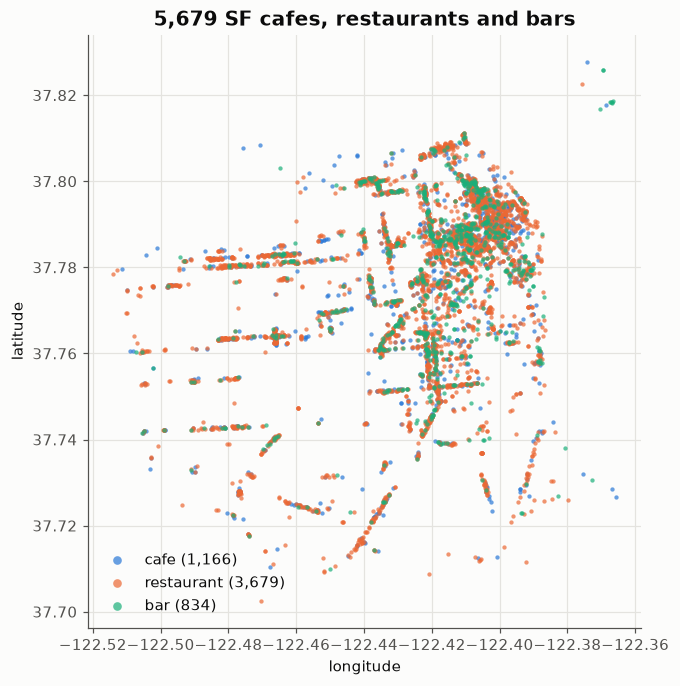

In [5]:
fig, ax = plt.subplots(figsize=(7, 7))
for group, color in GROUP_COLORS.items():
    sub = places[places["group"] == group]
    ax.scatter(sub["lon"], sub["lat"], s=8, color=color, alpha=0.7, linewidths=0,
               label=f"{group} ({len(sub):,})")
ax.set(title=f"{len(places):,} SF cafes, restaurants and bars", xlabel="longitude", ylabel="latitude")
ax.set_aspect(1.27)  # ~1/cos(37.8°): makes SF look the right shape
ax.legend(loc="lower left", markerscale=2)
plt.show()

## 4. Reviews

The reviews file is 5.35 GB compressed, too big for most laptops' free disk, so it is streamed
from the URL and only SF rows are kept. This takes 30-45 minutes, so the cell reuses
`sf_reviews.parquet` if it already exists.

Per place we keep the 50 most recent reviews with text. Google-translated reviews keep only
their English part.

In [6]:
reviews = pd.read_parquet(f.REVIEWS_OUT) if f.REVIEWS_OUT.exists() else f.build_reviews()
print(f"{len(reviews):,} reviews for {reviews['gmap_id'].nunique():,} of {len(places):,} places")
print(f"date range: {reviews['time'].min():%Y-%m} to {reviews['time'].max():%Y-%m}")
reviews.head()

212,176 reviews for 5,669 of 5,679 places
date range: 1990-12 to 2021-09


,gmap_id,time,rating,text
0,0x1532f625be01a5b5:0x50b4c080bd5a524b,2021-04-22 00:27:40.173,3.0,Love going to Philz to get a cup of coffee ☕ they know you by name and what ...
1,0x1532f625be01a5b5:0x50b4c080bd5a524b,2021-04-17 17:13:36.508,5.0,Wonderful local coffee shop with the friendliest staff and a warm vibe.
2,0x1532f625be01a5b5:0x50b4c080bd5a524b,2021-04-14 01:06:26.803,5.0,"Excellent service, every time. We lived next door and frequented - now that ..."
3,0x1532f625be01a5b5:0x50b4c080bd5a524b,2021-04-12 00:19:59.127,5.0,Great tasting tea and breakfast sandwiches. Good customer service.
4,0x1532f625be01a5b5:0x50b4c080bd5a524b,2021-04-06 23:46:20.280,5.0,So far the best drinks aside from the original 24th st Barista who was suoer...
